## Pegasus Evaluation: Depth

Section B.3. Setup, methods and metrics: `2a_base_case.ipynb`; parameters: `pegasus/evaluation_setup.py`.
B.3 runs on `tree_source`.

In [1]:
# Data source of B.3:
# - "real": the fork-join trees measured by the second testbed campaign (statics/results_milos_v2/b3/, pegasus/real_data.py)
# - "synthetic": balanced trees of the three generated services of B.1, with a simulated ground truth (pegasus/trees.py)
tree_source = "real"

# the parameters and helpers that every evaluation notebook shares, defined once in pegasus/evaluation_setup.py
from pegasus.evaluation_setup import *
import pandas as pd
from pegasus.figures import math_label, sweep_table, time_table
p_label = math_label(p_label)   # the quantile name in the math notation of the paper, e.g. $P_{95}$, for the figures and the text
# synthetic trees reuse the configurations and the training data of the synthetic base case of B.1, read from
# statics/evaluation_cache/ or computed here (b1_base); the measured trees need no base case
if tree_source == "synthetic":
    globals().update(b1_base("synthetic"))
print(f"{tree_source} trees, {len(seeds)} seeds")

real trees, 3 seeds


### B.3 Varying Depth of a Map-Reduce Application

Fork-join trees: the leaves alternate between two detectors, every inner service is an aggregator; every frame goes to
all leaves, and the root releases it once both children of every aggregator have. A *balanced* tree with $h$ levels
(`tree_levels`) has $2^h - 1$ services, because every aggregator has two children, so level $i$ holds $2^{i-1}$ services.
Every method bounds each leaf-to-root path and takes the maximum over the paths (`compare_tree_methods`).

- **Real (`tree_source = "real"`):** the balanced trees measured in `statics/results_milos_v2/b3/` (object and face
  detector as leaves, image transformer as aggregator, one worker each). Every service type is trained on its grid
  benchmark (`TREE_BENCHMARKS` in `pegasus/real_data.py`), which measured every configuration of the service alone: the
  face detector and the image transformer on `benchmark-grid15/` (cores capped at 1.5), the object detector on
  `benchmark-grid/`, because `benchmark-grid15/` does not contain it. Both grids give the same processing times for the
  same configuration. Held-out runs: throttled for less than `TREE_THROTTLE_LIMIT` of their CPU periods.
- **Synthetic (`tree_source = "synthetic"`):** balanced trees of the three services of B.1, Poisson arrivals at
  `tree_utilization` of the slowest service.
- **Methods:** as in B.1 without DNN Sum; both versions of Pegasus.

Figures: `figures/tsc/b3_trees_<tree source>` (tightness, training and evaluation time).

In [2]:
# the options of the data source of B.3
tree_setup = configure(tree_source)
if "B.3" in tree_setup["skipped"]:
    print("B.3 skipped: not supported by the {} data".format(tree_source))
else:
    tree_levels = tree_setup["tree_levels"]
    tree_seeds = tree_setup["tree_seeds"]   # the seeds of every experiment
    # B.3: balanced fork-join trees, (shape, levels) -> (children, the service type or node of every position); the shape
    # "balanced" stays in the key, because the results are keyed by shape (sweep_statistics below)
    if tree_source == "synthetic":   # pegasus/trees.py
        trees = {("balanced", h): balanced_tree(h) for h in tree_levels}
        tree_experiments = None
    else:                            # the topology of every measured balanced tree (tree_structure in pegasus/real_data.py)
        tree_experiments = tree_setup["tree_experiments"]
        trees = {key: tree_structure(experiment)[:2] for key, experiment in tree_experiments.items()}
    # the synthetic trees reuse the configurations and the training data of the synthetic base case of B.1 (setup cell)
    tree_bases = bases if tree_source == "synthetic" else None

    def compute():
        def tree_data(shape, levels, s):
            children, path = trees[(shape, levels)]
            if tree_source == "real":   # the measured runs of the tree, every service trained on its benchmark
                return real_tree_data(tree_experiments[(shape, levels)], level=1 - alpha, node_level=1 - alpha / len(path),
                                      coverage_check=coverage_check, seed=[seed, s], **tree_setup["base_options"])
            data = synthetic_tree_data(children, path, level=1 - alpha, node_level=1 - alpha / len(path), coverage_check=coverage_check,
                                       seed=[seed, s], utilization=tree_setup["tree_utilization"], service_seed=s)
            # the configurations and training data of B.1, every configuration with one worker
            assert same_configurations(model_inputs(data.x_test, data.workers_column), model_inputs(tree_bases[s].x_test, tree_bases[s].workers_column)), \
                "the held-out configurations differ from those of B.1"
            assert all(np.array_equal(data.y_train[name], tree_bases[s].y_train[name]) for name in data.y_train), "the training data differs from that of B.1"
            assert_unseen(data)
            return data

        tree_truth, tree_methods, tree_seconds = {}, {}, {}   # shape -> (levels, seed) -> ...
        with warnings.catch_warnings():
            # for some services the fitted GP hyperparameters end at their bounds, and scikit-learn warns for every such model
            warnings.simplefilter("ignore", ConvergenceWarning)
            for s in tree_seeds:
                for shape, levels in trees:
                    data = tree_data(shape, levels, s)
                    models = fit_services(data, data.x_train, data.y_train, model_seed=seed + s, confidence=confidence, with_dnn=False)
                    tree_methods.setdefault(shape, {})[(levels, s)], tree_seconds.setdefault(shape, {})[(levels, s)] = compare_tree_methods(
                        data, models, alpha, confidence, n_calibration, model_seed=seed + s, leave_out=only_base_case)
                    tree_truth.setdefault(shape, {})[(levels, s)] = (data.measured, data.measured_low)
                print(f"seed {s}: {len(trees)} trees evaluated")
        return dict(tree_truth=tree_truth, tree_methods=tree_methods, tree_seconds=tree_seconds)

    globals().update(cached("b3_trees", tree_source, compute, inputs=dict(
        tree_levels=tree_levels, tree_seeds=tree_seeds, tree_options=dict(tree_utilization=tree_setup.get("tree_utilization"), tree_experiments=tree_experiments))))

seed 0: 4 trees evaluated
seed 1: 4 trees evaluated
seed 2: 4 trees evaluated
b3_trees: results computed and saved to statics/evaluation_cache/b3_trees_real+b1+b1u-max3_7f4659ad6f0ed130.joblib


B.3 balanced fork-join trees, real data: leaves object and face detector, aggregators image transformer, one worker each, 96 to 100 held-out runs per tree,
Poisson arrivals at 50% utilization of the slowest service, 3 seeds (training draws)
legend_inside: the legend hides 4 points or bands at its best location (upper center)


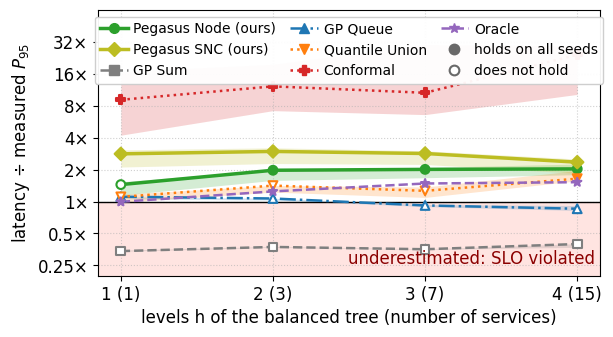

legend_inside: the legend hides 3 points or bands at its best location (upper center)
legend_inside: the legend hides 6 points or bands at its best location (upper center)


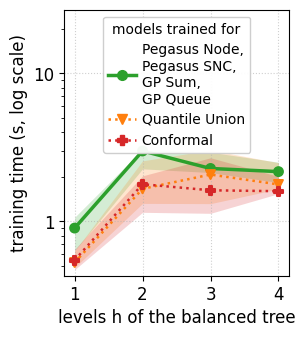

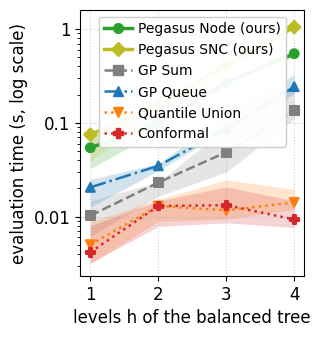

In [3]:
if "B.3" in tree_setup["skipped"]:
    print("B.3 skipped: not supported by the {} data".format(tree_source))
else:
    tree_statistics = sweep_statistics(tree_methods["balanced"], tree_truth["balanced"], tree_levels, tree_seeds, confidence)   # name -> coverage, tightness, holds, computed
    tree_times = sweep_seconds(tree_seconds["balanced"], tree_levels, tree_seeds)                                             # name -> training, evaluation
    size_ticks = [f"{h} ({len(trees[('balanced', h)][1])})" for h in tree_levels]   # one row: the fixed layout of every figure
    if tree_source == "synthetic":
        title = (f"B.3 balanced fork-join trees, synthetic data: leaves s1, s2, aggregators s3, one worker each, "
                 f"{len(base.measured)} held-out configurations per seed,\n{workload['process']} arrivals at "
                 f"{tree_setup['tree_utilization']:.0%} utilization of the slowest service, {len(tree_seeds)} seeds")
    else:
        from pegasus.real_data import run_table
        # the utilization of the slowest service at which the campaign set the arrival rate of every run
        tree_utilization = sorted({float(u) for experiment in tree_experiments.values() for u in run_table(experiment)["utilization_asked"]})
        held_out = sorted({len(measured) for measured, _ in tree_truth["balanced"].values()})   # held-out runs of every tree
        runs_text = f"{held_out[0]}" if len(held_out) == 1 else f"{held_out[0]} to {held_out[-1]}"
        title = (f"B.3 balanced fork-join trees, real data: leaves object and face detector, aggregators image transformer, "
                 f"one worker each, {runs_text} held-out runs per tree,\nPoisson arrivals at "
                 f"{' and '.join(f'{u:.0%}' for u in tree_utilization)} utilization of the slowest service, {len(tree_seeds)} seeds (training draws)")
    tightness_and_time_figure(tree_levels, tree_statistics, tree_times, "levels h of the balanced tree (number of services)",
                              title, p_label, tick_labels=size_ticks, log_x=False, name=f"b3_trees_{tree_source}",
                              # the two time figures side by side in the width of one: too narrow for "h (N)" at every tick, and the
                              # tightness figure already gives N for every h
                              time_halves=("levels h of the balanced tree", [str(h) for h in tree_levels]))

In [4]:
if "B.3" in tree_setup["skipped"]:
    print("B.3 skipped: not supported by the {} data".format(tree_source))
else:
    tree_label = lambda h: f"h = {h} ({len(trees[('balanced', h)][1])})"   # levels (number of services)
    print(f"Balanced trees ({tree_source} data; tightness, median over the seeds; ● holds, ○ does not):")
    display(sweep_table(tree_levels, tree_statistics, sweep_competitors + ["Oracle"], tree_label, tree_truth["balanced"], tree_seeds))
    print("Training and evaluation time (s, median over the seeds):")
    display(time_table(tree_levels, tree_times, sweep_competitors, tree_label))

Balanced trees (real data; tightness, median over the seeds; ● holds, ○ does not):


,h = 1 (1),h = 2 (3),h = 3 (7),h = 4 (15)
Pegasus Node (ours),1.44× ○,1.97× ●,2.01× ●,2.03× ●
Pegasus SNC (ours),2.81× ●,2.96× ●,2.83× ●,2.35× ●
GP Sum,0.34× ○,0.37× ○,0.36× ○,0.40× ○
GP Queue,1.11× ○,1.07× ○,0.92× ○,0.85× ○
Quantile Union,1.11× ○,1.41× ○,1.26× ○,1.64× ●
Conformal,9.07× ●,12.15× ●,10.56× ●,24.09× ●
Oracle,0.99× ●,1.24× ●,1.48× ●,1.52× ●
measured (s),0.202,0.244,0.468,0.148


Training and evaluation time (s, median over the seeds):


,h = 1 (1),h = 2 (3),h = 3 (7),h = 4 (15)
"training: Pegasus Node (ours), Pegasus SNC (ours), GP Sum, GP Queue",0.9,3,2.3,2.2
training: Quantile Union,0.53,1.7,2.1,1.8
training: Conformal,0.55,1.8,1.6,1.6
evaluation: Pegasus Node (ours),0.054,0.097,0.27,0.55
evaluation: Pegasus SNC (ours),0.075,0.15,0.42,1
evaluation: GP Sum,0.01,0.023,0.049,0.14
evaluation: GP Queue,0.021,0.035,0.086,0.24
evaluation: Quantile Union,0.005,0.013,0.012,0.014
evaluation: Conformal,0.0042,0.013,0.013,0.0093
